# Assignment 1: CO₂ Emissions by Country

**Course:** Foundation of Data Science

## 1. Dataset Loading and Initial Exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
import pandas as pd

df = pd.read_csv("co2_emissions_kt_by_country.csv")

df.head()

,country_code,country_name,year,value
0,ABW,Aruba,1960,11092.675
1,ABW,Aruba,1961,11576.719
2,ABW,Aruba,1962,12713.489
3,ABW,Aruba,1963,12178.107
4,ABW,Aruba,1964,11840.743


In [3]:
df.shape

(13953, 4)

In [4]:
df.columns.tolist()

['country_code', 'country_name', 'year', 'value']

The dataset contains 13,953 observations and four columns. Each observation represents CO₂ emissions for a country or region in a particular year.

## 2. Data Cleaning

Before performing statistical analysis, the dataset is checked for missing values, duplicate observations, and invalid entries.

In [5]:
df.isnull().sum()

country_code    0
country_name    0
year            0
value           0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.duplicated(subset=["country_code", "year"]).sum()

np.int64(0)

In [8]:
df.dtypes

country_code        str
country_name        str
year              int64
value           float64
dtype: object

In [9]:
(df["value"] < 0).sum()

np.int64(1)

In [10]:
df[df["value"] < 0]

,country_code,country_name,year,value
11002,SEN,Senegal,1968,-80.674


In [11]:
df_clean = df[df["value"] >= 0].copy()

In [12]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining negative values:", (df_clean["value"] < 0).sum())

Original dataset: (13953, 4)
Cleaned dataset: (13952, 4)
Remaining negative values: 0


### Handling Invalid Values

The dataset was checked for negative CO₂ emissions values. One negative observation was identified for Senegal in 1968, with a reported value of −80.674 kt.

Because the variable represents total CO₂ emissions, this observation was considered invalid for the analysis and excluded. The original dataset was preserved, while a cleaned version (`df_clean`) was created.

After this operation, the cleaned dataset contains 13,952 observations, with no remaining negative emissions values.

In [13]:
print("Zero emissions values:", (df_clean["value"] == 0).sum())

Zero emissions values: 21


In [14]:
df_clean[df_clean["value"] == 0]

,country_code,country_name,year,value
3692,ERI,Eritrea,1990,0.0
3693,ERI,Eritrea,1991,0.0
4229,FSM,"Micronesia, Fed. Sts.",1990,0.0
4230,FSM,"Micronesia, Fed. Sts.",1991,0.0
8165,MHL,Marshall Islands,1990,0.0
8166,MHL,Marshall Islands,1991,0.0
8321,MLI,Mali,1996,0.0
9980,PLW,Palau,1990,0.0
9981,PLW,Palau,1991,0.0
12459,TLS,Timor-Leste,1990,0.0


The dataset contains 21 observations with zero CO₂ emissions. These observations were retained because zero is a possible reported value and cannot be classified as invalid without additional information.

In [15]:
df_clean[
    df_clean["country_name"].str.contains(
        "World|income|OECD|European Union",
        case=False,
        na=False
    )
]["country_name"].unique()

<StringArray>
[                                        'Arab World',
        'East Asia & Pacific (excluding high income)',
      'Europe & Central Asia (excluding high income)',
                                     'European Union',
                                        'High income',
  'Latin America & Caribbean (excluding high income)',
                                         'Low income',
                                'Lower middle income',
                                'Low & middle income',
                                      'Middle income',
 'Middle East & North Africa (excluding high income)',
                                       'OECD members',
         'Sub-Saharan Africa (excluding high income)',
                                'Upper middle income',
                                              'World']
Length: 15, dtype: str

In [16]:
import pycountry

valid_country_codes = {
    country.alpha_3
    for country in pycountry.countries
}

This provides standardized country information, alpha_3 represents three letter iso country codes.

In [17]:
# Include Kosovo in the country codes
valid_country_codes.add("XKX")

df_countries = df_clean[
    df_clean["country_code"].isin(valid_country_codes)
].copy()

print("Cleaned observations:", len(df_clean))
print("Country-level observations:", len(df_countries))
print("Excluded observations:", len(df_clean) - len(df_countries))
print("Number of countries:", df_countries["country_name"].nunique())

Cleaned observations: 13952
Country-level observations: 11102
Excluded observations: 2850
Number of countries: 208


.isin() checks whether each country_code appears in ISO country code list.

In [18]:
excluded_names = df_clean.loc[
    ~df_clean["country_code"].isin(valid_country_codes),
    "country_name"
].unique()

print(excluded_names)

<StringArray>
[                         'Africa Eastern and Southern',
                           'Africa Western and Central',
                                           'Arab World',
                       'Central Europe and the Baltics',
                               'Caribbean small states',
          'East Asia & Pacific (excluding high income)',
                           'Early-demographic dividend',
                                  'East Asia & Pacific',
        'Europe & Central Asia (excluding high income)',
                                'Europe & Central Asia',
                                            'Euro area',
                                       'European Union',
             'Fragile and conflict affected situations',
                                          'High income',
               'Heavily indebted poor countries (HIPC)',
                                            'IBRD only',
                                     'IDA & IBRD total',
                 

In [19]:
print("Number of countries:", df_countries["country_name"].nunique())
print("Number of observations:", df_countries.shape[0])
print("Remaining negative values:", (df_countries["value"] < 0).sum())

Number of countries: 208
Number of observations: 11102
Remaining negative values: 0


### Data Cleaning Summary

The dataset was examined for missing values, duplicate observations, and invalid emissions values.

No missing values or duplicate country-year observations were identified. One negative emissions value was found for Senegal in 1968 (−80.674 kt), which was excluded because it was considered invalid for the analysis.

The dataset also contained 21 observations with zero emissions. These were retained because zero values are not necessarily errors.

Regional and economic aggregates were excluded using ISO country codes, with Kosovo (`XKX`) included separately.

After cleaning, the dataset contains **11,102 observations representing 208 countries and territories**. This dataset will be used for the subsequent analysis.

## 3. Descriptive Statistics

For the descriptive analysis, the year 2019 was selected because it is the most recent year available in the dataset.

However, we don't know the population of each country from this CSV. To calculate emissions per capita, we use: Co2 per capita = co2 emissions (kt)* 1000/ population
For this, we'll use population data from the World Bank.

In [20]:
df_2019 = df_countries[df_countries["year"] == 2019].copy()

print("Countries with data in 2019:", len(df_2019))

display(df_2019.head())

Countries with data in 2019: 191


,country_code,country_name,year,value
176,AFG,Afghanistan,2019,6079.999924
296,AGO,Angola,2019,25209.999084
356,ALB,Albania,2019,4829.999924
386,AND,Andorra,2019,500.000000
506,ARE,United Arab Emirates,2019,188860.000610


In [21]:
import glob

glob.glob("API_SP.POP.TOTL*.csv")

['API_SP.POP.TOTL_DS2_en_csv_v2_5254.csv']

In [22]:
population_file = glob.glob("API_SP.POP.TOTL*.csv")[0]

df_population = pd.read_csv(population_file, skiprows=4)

df_population.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,107995.0,108785.0,NaN
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130075728.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750491370.0,769280888.0,788844284.0,NaN
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,42647492.0,43844111.0,NaN
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106384410.0,108754449.0,...,440150152.0,451395343.0,462522286.0,473687685.0,484978794.0,496366058.0,508318102.0,520655398.0,532809933.0,NaN
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,37885849.0,39040039.0,NaN


In [23]:
print("Population dataset shape:", df_population.shape)

print("\nColumn names:")
print(df_population.columns.tolist())

Population dataset shape: (266, 71)

Column names:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', 'Unnamed: 70']


In [24]:
df_population_2019 = df_population[
    ["Country Name", "Country Code", "2019"]
].copy()

df_population_2019.head()

,Country Name,Country Code,2019
0,Aruba,ABW,109203.0
1,Africa Eastern and Southern,AFE,675950189.0
2,Afghanistan,AFG,37856121.0
3,Africa Western and Central,AFW,462522286.0
4,Angola,AGO,32375632.0


We need to merge Co2 emissions with population data

In [25]:
df_population_2019 = df_population_2019.rename(
    columns={
        "Country Code": "country_code",
        "2019": "population"
    }
)

df_population_2019.head()

,Country Name,country_code,population
0,Aruba,ABW,109203.0
1,Africa Eastern and Southern,AFE,675950189.0
2,Afghanistan,AFG,37856121.0
3,Africa Western and Central,AFW,462522286.0
4,Angola,AGO,32375632.0


In [26]:
df_merged = pd.merge(
    df_2019,
    df_population_2019[["country_code", "population"]],
    on="country_code",
    how="left",
    validate="one_to_one"
)

df_merged.head()

,country_code,country_name,year,value,population
0,AFG,Afghanistan,2019,6079.999924,37856121.0
1,AGO,Angola,2019,25209.999084,32375632.0
2,ALB,Albania,2019,4829.999924,2567801.0
3,AND,Andorra,2019,500.000000,76474.0
4,ARE,United Arab Emirates,2019,188860.000610,9445785.0


In [27]:
print("Countries before merge:", len(df_2019))
print("Countries after merge:", len(df_merged))

print("Missing population values:")
print(df_merged["population"].isnull().sum())

Countries before merge: 191
Countries after merge: 191
Missing population values:
0


In [28]:
df_merged[df_merged["population"].isnull()][
    ["country_code", "country_name"]
]

,country_code,country_name


In [29]:
df_merged["co2_per_capita"] = (
    df_merged["value"] * 1000
) / df_merged["population"]

df_merged.head()

,country_code,country_name,year,value,population,co2_per_capita
0,AFG,Afghanistan,2019,6079.999924,37856121.0,0.160608
1,AGO,Angola,2019,25209.999084,32375632.0,0.778672
2,ALB,Albania,2019,4829.999924,2567801.0,1.880987
3,AND,Andorra,2019,500.000000,76474.0,6.538170
4,ARE,United Arab Emirates,2019,188860.000610,9445785.0,19.994103


In [30]:
print("Missing values:",
      df_merged["co2_per_capita"].isnull().sum())

print("Negative values:",
      (df_merged["co2_per_capita"] < 0).sum())

print("Infinite values:",
      np.isinf(df_merged["co2_per_capita"]).sum())

print("Minimum population:",
      df_merged["population"].min())

Missing values: 0
Negative values: 0
Infinite values: 0
Minimum population: 10581.0


### Calculation of CO₂ Emissions per Capita

The CO₂ emissions dataset was combined with World Bank population data for 2019 using country codes.

The merge retained all 191 country observations, with no missing population values.

Since the original emissions values are measured in kilotonnes (kt), they were converted into tonnes by multiplying by 1,000. The resulting emissions were then divided by each country's population to obtain CO₂ emissions per capita, measured in tonnes per person.

### Descriptive Statistics for 2019

The following statistics summarize the distribution of CO₂ emissions per capita across 191 countries in 2019. Emissions are measured in tonnes per person.

In [31]:
co2_values = df_merged["co2_per_capita"]

print("Number of observations:", co2_values.count())

Number of observations: 191


In [32]:
mean_co2 = co2_values.mean()

print("Mean CO₂ emissions per capita:", round(mean_co2, 3))

Mean CO₂ emissions per capita: 4.142


In [33]:
median_co2 = co2_values.median()

print("Median CO₂ emissions per capita:", round(median_co2, 3))

Median CO₂ emissions per capita: 2.718


In [34]:
print("Mean:", round(mean_co2, 3))
print("Median:", round(median_co2, 3))

Mean: 4.142
Median: 2.718


In [35]:
mode_co2 = co2_values.mode()

print("Mode:")
print(mode_co2)

Mode:
0       0.034536
1       0.043042
2       0.048537
3       0.058750
4       0.076212
         ...    
186    17.422284
187    19.994103
188    20.856238
189    22.416083
190    34.854853
Name: co2_per_capita, Length: 191, dtype: float64


In [36]:
co2_values.value_counts().head()

co2_per_capita
0.160608     1
0.778672     1
1.880987     1
6.538170     1
19.994103    1
Name: count, dtype: int64

In [37]:
min_co2 = co2_values.min()
max_co2 = co2_values.max()

range_co2 = max_co2 - min_co2

print("Minimum:", round(min_co2, 3))
print("Maximum:", round(max_co2, 3))
print("Range:", round(range_co2, 3))

Minimum: 0.035
Maximum: 34.855
Range: 34.82


In [38]:
variance_co2 = co2_values.var(ddof=1)

print("Sample variance:", round(variance_co2, 3))

Sample variance: 23.5


In [39]:
std_co2 = co2_values.std(ddof=1)

print("Sample standard deviation:", round(std_co2, 3))

Sample standard deviation: 4.848


In [40]:
q1 = co2_values.quantile(0.25)
q3 = co2_values.quantile(0.75)

iqr_co2 = q3 - q1

print("Q1:", round(q1, 3))
print("Q3:", round(q3, 3))
print("IQR:", round(iqr_co2, 3))

Q1: 0.784
Q3: 5.592
IQR: 4.808


In [41]:
print("Highest frequency:", co2_values.value_counts().max())

Highest frequency: 1


### Summary of Descriptive Statistics

In [42]:
summary_stats = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Median",
        "Mode",
        "Minimum",
        "Maximum",
        "Range",
        "Sample Variance",
        "Sample Standard Deviation",
        "Q1",
        "Q3",
        "IQR"
    ],
    "Value": [
        round(mean_co2, 3),
        round(median_co2, 3),
        "No unique mode",
        round(min_co2, 3),
        round(max_co2, 3),
        round(range_co2, 3),
        round(variance_co2, 3),
        round(std_co2, 3),
        round(q1, 3),
        round(q3, 3),
        round(iqr_co2, 3)
    ]
})

display(summary_stats)

,Statistic,Value
0,Mean,4.142
1,Median,2.718
2,Mode,No unique mode
3,Minimum,0.035
4,Maximum,34.855
5,Range,34.82
6,Sample Variance,23.5
7,Sample Standard Deviation,4.848
8,Q1,0.784
9,Q3,5.592


### Interpretation of Descriptive Statistics

The descriptive statistics indicate considerable differences in CO₂ emissions per capita across the 191 countries analyzed in 2019.

The mean emissions per capita were 4.142 tonnes, while the median was 2.718 tonnes. Since the mean is higher than the median, the distribution appears to be positively skewed, suggesting that countries with particularly high emissions influence the average.

The range of 34.820 tonnes per person demonstrates substantial differences between the lowest and highest observations.

Furthermore, the standard deviation of 4.848 and the interquartile range of 4.808 indicate considerable variation across countries. The middle 50% of observations fall between 0.784 and 5.592 tonnes per person.

No unique mode was identified because each country had a different emissions-per-capita value.

## 4. Data Visualization

### 4.1 Histogram of CO₂ Emissions per Capita

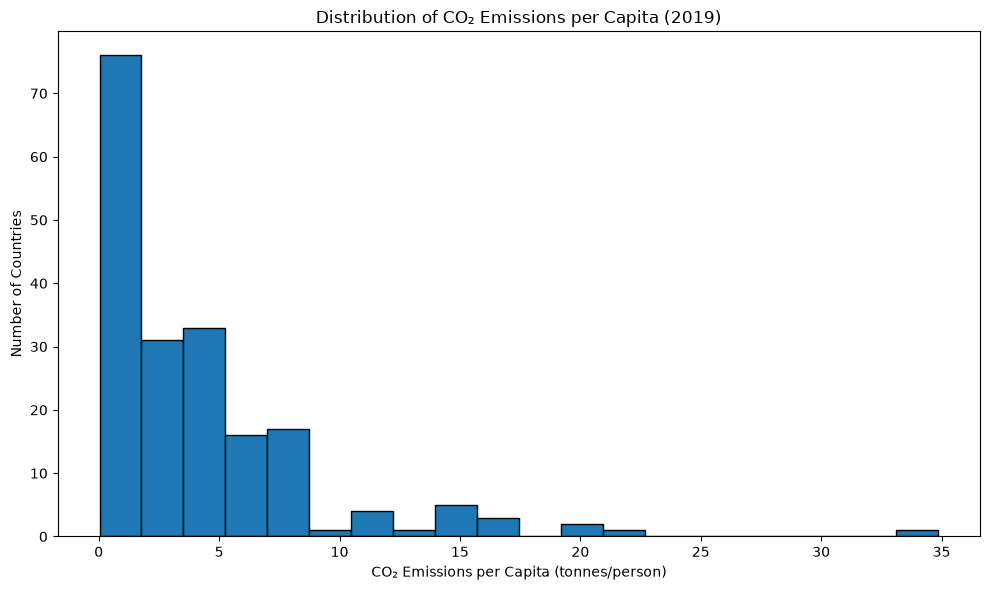

In [43]:
plt.figure(figsize=(10, 6))

plt.hist(
    co2_values,
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of CO₂ Emissions per Capita (2019)")
plt.xlabel("CO₂ Emissions per Capita (tonnes/person)")
plt.ylabel("Number of Countries")

plt.tight_layout()
plt.show()

### Histogram Interpretation

The histogram shows a positively skewed distribution of CO₂ emissions per capita in 2019. Most countries are concentrated at relatively low emissions levels, particularly below 5 tonnes per person.

As emissions per capita increase, the number of countries decreases. A small number of countries have substantially higher emissions, creating a long right tail.

This pattern is consistent with the mean (4.142) being higher than the median (2.718), suggesting considerable differences in emissions per capita across countries.

### 4.2 Boxplot of CO₂ Emissions per Capita

/var/folders/b8/272cvj217ml097tf6bjpnbxc0000gn/T/ipykernel_3898/4013747615.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


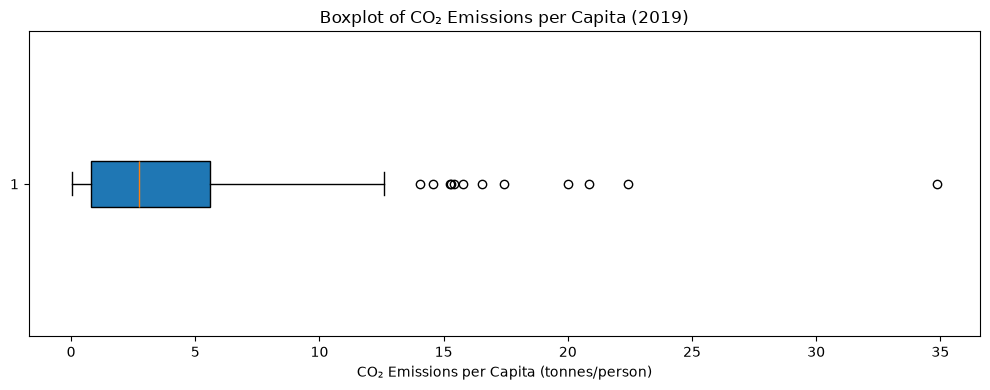

In [44]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    co2_values,
    vert=False,
    patch_artist=True
)

plt.title("Boxplot of CO₂ Emissions per Capita (2019)")
plt.xlabel("CO₂ Emissions per Capita (tonnes/person)")

plt.tight_layout()
plt.show()

In [45]:
lower_bound = q1 - 1.5 * iqr_co2
upper_bound = q3 + 1.5 * iqr_co2

outliers = df_merged[
    (df_merged["co2_per_capita"] < lower_bound) |
    (df_merged["co2_per_capita"] > upper_bound)
].copy()

print("Lower bound:", round(lower_bound, 3))
print("Upper bound:", round(upper_bound, 3))
print("Number of outliers:", len(outliers))

display(
    outliers[
        ["country_name", "co2_per_capita"]
    ].sort_values("co2_per_capita", ascending=False)
)

Lower bound: -6.429
Upper bound: 12.805
Number of outliers: 12


,country_name,co2_per_capita
143,Qatar,34.854853
17,Bahrain,22.416083
94,Kuwait,20.856238
4,United Arab Emirates,19.994103
147,Saudi Arabia,17.422284
132,Oman,16.559793
25,Brunei Darussalam,15.790187
29,Canada,15.423531
104,Luxembourg,15.306427
8,Australia,15.256864


### Boxplot Interpretation

The boxplot confirms that the distribution of CO₂ emissions per capita in 2019 is positively skewed.

The median is 2.718 tonnes per person, while the middle 50% of countries have emissions between 0.784 and 5.592 tonnes per person.

Using the 1.5 × IQR method, 12 countries were identified as potential outliers, all above the upper threshold of 12.805 tonnes per person.

Qatar has the highest emissions per capita, at approximately 34.855 tonnes per person, followed by Bahrain and Kuwait.

These results suggest substantial differences in CO₂ emissions per capita across countries. The outliers were retained because unusually high values are not automatically data errors.

## 5. Confidence Interval for Mean CO₂ Emissions per Capita

A 95% confidence interval is calculated to estimate the mean CO₂ emissions per capita across countries in 2019.

In [46]:
n = co2_values.count()

standard_error = std_co2 / np.sqrt(n)

print("Number of observations:", n)
print("Standard error:", round(standard_error, 4))

Number of observations: 191
Standard error: 0.3508


In [47]:
from scipy import stats

confidence_level = 0.95
degrees_of_freedom = n - 1

t_critical = stats.t.ppf(
    (1 + confidence_level) / 2,
    df=degrees_of_freedom
)

print("Degrees of freedom:", degrees_of_freedom)
print("Critical t-value:", round(t_critical, 4))

Degrees of freedom: 190
Critical t-value: 1.9725


In [48]:
margin_of_error = t_critical * standard_error

ci_lower = mean_co2 - margin_of_error
ci_upper = mean_co2 + margin_of_error

print("Sample mean:", round(mean_co2, 3))
print("Margin of error:", round(margin_of_error, 3))
print("95% Confidence Interval:")
print("Lower bound:", round(ci_lower, 3))
print("Upper bound:", round(ci_upper, 3))

Sample mean: 4.142
Margin of error: 0.692
95% Confidence Interval:
Lower bound: 3.45
Upper bound: 4.834


### Interpretation of the 95% Confidence Interval

The estimated mean CO₂ emissions per capita across the 191 countries in 2019 was 4.142 tonnes per person.

Using the Student's t-distribution, a standard error of 0.3508 and a critical t-value of 1.9725, the calculated 95% confidence interval was between 3.450 and 4.834 tonnes per person.

Under the assumptions of the confidence interval method, this interval provides a plausible range for the mean emissions per capita across countries.

However, because the dataset is based on available country observations rather than a random sample, the confidence interval should be interpreted cautiously.

## 6. Discussion: Global CO₂ Emission Inequality and Limitations

### Discussion

The results indicate substantial inequality in CO₂ emissions per capita across countries in 2019.

The mean of 4.142 tonnes per person was higher than the median of 2.718 tonnes, suggesting a positively skewed distribution. The histogram confirmed that most countries had relatively low emissions, while a smaller number had substantially higher values.

The boxplot identified 12 high-emission outliers, including Qatar, Bahrain, and Kuwait. Qatar had the highest observed emissions per capita, at approximately 34.855 tonnes per person.

These findings demonstrate considerable differences in emissions per capita between countries, although they do not explain the causes of those differences.

**Limitations**

The analysis covers only 2019 and therefore cannot identify long-term trends. Furthermore, the country-level mean gives equal weight to each country regardless of population size, so it should not be interpreted as the global average emissions per person.

The analysis includes 191 countries with available data, and differences in reporting or measurement may affect comparability. The results also do not account fully for emissions associated with imported goods and services.

Finally, because the countries were not randomly sampled, the 95% confidence interval should be interpreted cautiously.